# Gap to the Podium: Phase 4 trajectories

Is India's gap to the podium already there at age 18? Every season best becomes a performance
index (100 = bronze level, higher is better), lined up by the athlete's age. Indian athletes are
compared with the 2024 Olympic finalists (Indian finalists left out).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd

from src.analysis import average_over_games, match_medallists, season_best_bronze
from src.trajectory import pick_thresholds
from src.warehouse import query, table

gap = table("marts.mart_gap_to_podium")
toplists = table("staging.stg_wa_toplists")
podium = query("""
    SELECT championship_year, event_key, athlete_name, country_code, position, mark_value,
           higher_is_better, discipline_group
    FROM staging.stg_olympic_results
    WHERE position BETWEEN 1 AND 3 AND championship_year IN (2016, 2020, 2024)
""")
sb = average_over_games(season_best_bronze(match_medallists(podium, toplists)))
thresholds = pick_thresholds(gap[["event_key", "bronze_threshold"]].merge(sb, on="event_key", how="left"))
print(thresholds["source"].value_counts())
thresholds[thresholds["source"] != "medallists' season bests"]

source
medallists' season bests    42
Name: count, dtype: int64


,event_key,threshold,source


In [2]:
from src.config import RAW_DIR, SEEDS_DIR
from src.trajectory import age_aligned, latest_run, level_by_age, load_group

th = dict(zip(thresholds["event_key"], thresholds["threshold"]))
groups = {"India": ("wa", "india_athletes.csv", None),
          "Finalists": ("wa_finalists", "finalists_2024.csv", "IND")}
traj = {}
for name, (subdir, seed, exclude) in groups.items():
    run = latest_run(RAW_DIR / subdir)
    sbs, births = load_group(run, SEEDS_DIR / seed, exclude_country=exclude)
    traj[name] = age_aligned(sbs, births, th)
    print(f"{name}: run {run.name}, {traj[name]['wa_id'].nunique()} athletes, "
          f"{len(traj[name])} season bests")

India: run 20261006T193207Z, 72 athletes, 672 season bests
Finalists: run 20261011T143113Z, 305 athletes, 3353 season bests


In [3]:
levels = pd.concat({name: level_by_age(t).set_index("age") for name, t in traj.items()}, axis=1)
levels.loc[16:30].round(1)

India                    Finalists                    
    athletes median   q25   q75  athletes median   q25    q75
age                                                          
16        14   85.8  76.2  88.1       112   88.2  80.6   91.3
17        25   86.4  80.8  90.0       155   90.2  84.5   93.4
18        36   88.3  83.5  91.4       190   91.5  85.1   95.5
19        39   88.5  83.1  92.6       206   93.7  89.8   97.0
20        43   89.4  84.9  93.8       238   95.5  91.9   98.4
21        49   92.3  87.5  95.6       244   96.7  92.2   99.3
22        50   92.4  88.2  95.2       250   97.6  94.6   99.8
23        54   93.6  89.9  95.8       246   98.3  96.0  100.1
24        45   94.5  93.0  96.9       235   98.9  96.9  100.4
25        47   95.2  93.7  97.4       226   98.9  97.0  100.6
26        39   93.9  90.8  96.0       200   99.6  97.9  100.8
27        38   96.3  92.8  97.3       186   99.6  97.5  101.3
28        33   94.9  93.3  96.8       157   99.9  97.9  101.2
29        29   94.7  92.2  97.5       147   99.4  97.5  100.9
30        23   95.6  93.1  96.9       117   99.7  97.8  101.2

**First look (median performance index by age).** At 18, Indian athletes are about 3 points
(about 3%) further from bronze level than 2024 finalists (88.3 vs 91.5). The difference grows to
about 5-6 points at 19-20 and then stays at roughly 4-5 points through age 30; finalists level off
near 99-100 (bronze level), Indian athletes near 95. All 42 thresholds are medallists' season
bests. 72 Indian athletes, 305 finalists (Indian finalists left out).

**Caution.** Each age compares whichever athletes have a mark at that age, so the groups change
from age to age. This shows the gap exists at 18 but cannot say whether it grows: Phase 3's H2,
which follows the same athletes season to season, found Indian athletes improve at least as fast.
The mixed-effects model below follows each athlete's own line and settles it.

## 2. Mixed-effects model: does the gap start at 18, and does it grow?

Every athlete-event gets its own level and improvement rate (random effects); each group gets an
average curve with a level at 18, a yearly improvement and a bend (fixed effects). Ages 16-30,
age measured from 18. `india` = gap at 18; `india:years` = difference in yearly improvement.

In [4]:
from src.trajectory import fit_trajectory_model, group_effects, mean_curves, model_frame

frame = model_frame(traj["India"], traj["Finalists"])
result = fit_trajectory_model(frame)
print(f"converged: {result.converged}; {frame['unit'].nunique()} athlete-event lines, "
      f"{len(frame)} season bests")
group_effects(result).round(3)

converged: True; 396 athlete-event lines, 3596 season bests


,term,meaning,estimate,ci_low,ci_high,p_value
0,india,gap at 18 (points),-4.861,-6.749,-2.974,0.000
1,india:years,difference in improvement per year at 18 (points),-0.302,-0.613,0.010,0.058
2,india:I(years ** 2),difference in curvature (points per year squared),0.034,0.012,0.056,0.002


In [5]:
curves = mean_curves(result).pivot(index="age", columns="group", values="perf_index")
curves["gap"] = curves["Finalists"] - curves["India"]
curves.round(1)

group,Finalists,India,gap
age,,,
16,83.8,79.7,4.1
17,86.7,82.1,4.5
18,89.3,84.4,4.9
19,91.6,86.4,5.1
20,93.6,88.2,5.3
21,95.3,89.8,5.5
22,96.8,91.2,5.5
23,97.9,92.4,5.5
24,98.8,93.3,5.5


**Result.** The model (396 athlete-event lines, 3,596 season bests, ages 16-30) puts Indian
athletes 4.9 points behind finalists at age 18 (95% CI 3.0 to 6.7, p < 0.001), larger than the
raw medians (3.2) because it also uses athletes whose age-18 season is missing. Yearly improvement
at 18 is 0.3 points lower (CI -0.61 to +0.01, p = 0.058: not significant), and Indian curves bend
less (+0.034, p = 0.002), so India improves slightly slower until about 22 and slightly faster
after. Over 18-24 this roughly evens out, consistent with Phase 3's H2.

**Conclusion.** The gap is about 4 points at 16, 5 points at 18 and stays at 5-5.5 points through
the development years. It is set before 18 and carried, not built during the development years.
This locates when the gap appears, not why (talent, coaching and competition are not separable
here).

**Caution.** The narrowing after 26 (3.6 points at 30) is not a finding: a quadratic curve is
symmetric by construction, and Indian athletes still competing at 29-30 are likely the stronger
ones.

## 3. Robustness and diagnostics

Does the gap at 18 hold in every event family, for each sex, and without the decline years?
Gap shown as positive = India behind. Subsets with fewer than 8 athlete-event lines in either
group are not fitted.

In [6]:
from src.trajectory import residual_check, robustness, variance_parts

robust = robustness(frame)
robust.round(2)

,subset,indian_lines,finalist_lines,gap_at_18,gap_low,gap_high,slope_diff,slope_low,slope_high,converged,optimizer,note
0,all events,77,319,4.86,2.97,6.75,-0.30,-0.61,0.01,True,lbfgs,
1,combined events,2,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,too few lines to fit
2,endurance,30,105,7.84,5.03,10.66,0.35,-0.19,0.89,True,powell,"Gradient optimization failed, |grad| = 213; Ma..."
3,jumps,11,60,3.94,0.45,7.43,-0.13,-0.65,0.39,True,lbfgs,
4,sprints and hurdles,19,77,3.77,2.13,5.42,-0.15,-0.47,0.17,True,lbfgs,
5,throws,15,60,2.22,-2.13,6.57,-1.30,-2.00,-0.60,True,lbfgs,
6,men,41,161,4.45,1.80,7.09,-0.05,-0.48,0.39,True,lbfgs,
7,women,36,158,5.37,2.72,8.03,-0.58,-1.02,-0.13,True,lbfgs,
8,ages 16-28,75,317,5.00,3.04,6.95,-0.38,-0.73,-0.03,True,lbfgs,
9,cubic age curve,77,319,5.02,3.12,6.91,-0.66,-1.05,-0.26,True,lbfgs,


In [7]:
print(pd.Series(variance_parts(result)).round(2), "\n")
check = residual_check(result, frame)
check.pivot(index="age", columns="group", values="mean").round(2)

sd_level_at_18            6.79
sd_yearly_improvement     0.73
corr_level_improvement   -0.92
sd_season_noise           2.78
dtype: float64 



group,Finalists,India
age,,
16,-0.98,0.08
17,-0.34,0.09
18,0.06,-0.02
19,0.59,-0.31
20,0.76,-0.12
21,0.33,0.64
22,-0.15,-0.28
23,-0.11,-0.32
24,-0.24,0.28


In [8]:
pd.set_option("display.max_colwidth", None)
robust[["subset", "optimizer", "note"]]

,subset,optimizer,note
0,all events,lbfgs,
1,combined events,NaN,too few lines to fit
2,endurance,powell,"Gradient optimization failed, |grad| = 213; Maximum Likelihood optimization failed to converge; MixedLM optimization failed, trying a different optimizer may help; The Hessian matrix at the estimated parameter values is not positive definite"
3,jumps,lbfgs,
4,sprints and hurdles,lbfgs,
5,throws,lbfgs,
6,men,lbfgs,
7,women,lbfgs,
8,ages 16-28,lbfgs,
9,cubic age curve,lbfgs,


In [9]:
robust.drop(columns="note").round(2)

,subset,indian_lines,finalist_lines,gap_at_18,gap_low,gap_high,slope_diff,slope_low,slope_high,converged,optimizer
0,all events,77,319,4.86,2.97,6.75,-0.30,-0.61,0.01,True,lbfgs
1,combined events,2,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,endurance,30,105,7.84,5.03,10.66,0.35,-0.19,0.89,True,powell
3,jumps,11,60,3.94,0.45,7.43,-0.13,-0.65,0.39,True,lbfgs
4,sprints and hurdles,19,77,3.77,2.13,5.42,-0.15,-0.47,0.17,True,lbfgs
5,throws,15,60,2.22,-2.13,6.57,-1.30,-2.00,-0.60,True,lbfgs
6,men,41,161,4.45,1.80,7.09,-0.05,-0.48,0.39,True,lbfgs
7,women,36,158,5.37,2.72,8.03,-0.58,-1.02,-0.13,True,lbfgs
8,ages 16-28,75,317,5.00,3.04,6.95,-0.38,-0.73,-0.03,True,lbfgs
9,cubic age curve,77,319,5.02,3.12,6.91,-0.66,-1.05,-0.26,True,lbfgs


**Robustness.** The gap at 18 is positive in every fitted subset: sprints and hurdles 3.8 points
(95% CI 2.1 to 5.4), jumps 3.9 (0.5 to 7.4), men 4.5 (1.8 to 7.1), women 5.4 (2.7 to 8.0), ages
16-28 5.0 (3.0 to 7.0), and with a cubic age curve 5.0 (3.1 to 6.9), against 4.9 in the main model.
Exceptions: throws 2.2 (-2.1 to 6.6, not significant at 18, but Indian throwers improve 1.3 points
a year slower, CI -2.0 to -0.6; junior-implement marks are excluded, so throwers' seasons at 16-19
are sparse in both groups). Endurance shows the largest gap (7.8 points), but that fit needed the
fallback optimizer and its Hessian was not positive definite, so no interval is reported for it.
Combined events: too few athletes to fit.

**Slower improvement at 18** is borderline in the main model (p = 0.058) but significant with a
cubic curve (-0.66 points/year, CI -1.05 to -0.26), for women (-0.58), throws (-1.30) and ages
16-28 (-0.38): moderate evidence that Indian athletes improve slightly slower in their late teens.
Their curves bend less, so they keep improving longer, and over 18-24 the rates are similar
(consistent with Phase 3's H2).

**Diagnostics.** Athletes differ a lot at 18 (SD 6.8 points, larger than the 4.9-point gap, so the
groups overlap heavily); strong juniors improve less (level-improvement correlation -0.92); one
season best sits about 2.8 points off an athlete's trend. Leftover errors by age are within +/-1
point; the slight wave in the finalists' leftovers (careers rise faster in the late teens than a
quadratic allows) does not move the gap at 18 (cubic check above).

**Conclusion.** India's gap to the podium is established by age 18 (about 5 points, robust to event
family, sex, age window and curve shape) and then largely carried through the development years,
with at most a slightly slower start. Since the gap is set before 18, the place to close it is youth
development and talent identification; this analysis locates when the gap appears, not why.

## 4. Backtest: can the model predict seasons it has not seen?

Fit on seasons up to 2022; predict every 2023-2026 season of athlete-events with at least two
seasons by 2022, up to four seasons ahead. Five contenders: last season, last season plus the
typical change at that age, plain regression (group curve only), gradient boosting on the
athlete's history, and the mixed-effects model. Errors in index points; every run is logged to
MLflow.

In [10]:
from src.backtest import CUTOFF, MAX_HORIZON, MIN_HISTORY, log_to_mlflow, run_backtest, score

preds = run_backtest(frame)
scores = score(preds)
print(f"{preds['unit'].nunique()} athlete-events, {len(preds)} hidden seasons predicted "
      f"({(preds['india'] == 1).sum()} Indian)")
scores.round(2)

292 athlete-events, 899 hidden seasons predicted (126 Indian)


,contender,n,mae,rmse,bias,mae_h1,mae_h2,mae_h3,mae_h4,mae_india,mae_finalists,coverage_80
0,last_season,899,2.62,3.61,-1.53,1.91,2.48,2.84,3.48,3.23,2.52,NaN
1,age_trend,899,2.34,3.29,0.52,1.73,1.97,2.65,3.31,2.82,2.26,NaN
2,fixed_curve,899,2.96,3.72,-1.89,3.00,3.00,2.85,2.98,3.54,2.86,NaN
3,boosting,899,1.96,2.73,-0.67,1.61,1.85,2.14,2.36,2.43,1.88,0.82
4,mixed_model,899,2.39,3.28,-1.06,2.05,2.28,2.43,2.94,2.38,2.39,0.86


In [11]:
params = {"cutoff": CUTOFF, "min_history": MIN_HISTORY, "max_horizon": MAX_HORIZON,
          "model_ages": "16-30", "india_run": latest_run(RAW_DIR / "wa").name,
          "finalists_run": latest_run(RAW_DIR / "wa_finalists").name}
run_ids = log_to_mlflow(preds, scores, params)
print(f"{len(run_ids)} runs logged")

5 runs logged


**Backtest result** (fit on seasons to 2022; 899 hidden 2023-2026 seasons of 292 athlete-events,
126 Indian). Mean absolute error in index points: gradient boosting 1.96, age trend 2.34,
mixed model 2.39, last season 2.62, plain regression (group curve only) 2.96. Boosting is best at
every horizon (1.61 one season ahead, 2.36 four ahead). The mixed model is worse than "same as last
season" one season ahead (2.05 vs 1.91): it predicts an athlete's smoothed long-term line and
largely ignores recent form. For Indian athletes the two are level (mixed 2.38, boosting 2.43;
only 126 predictions). The mixed model's 80% intervals held 86% of real results (honest, slightly
wide). All models but age trend lean pessimistic (bias -0.67 to -1.89), consistent with finalists
being selected for good 2024 seasons.

**So far:** the mixed model remains the tool for explaining the gap; boosting is the stronger
forecaster overall. Next: check whether boosting's lead is real (athlete-level bootstrap) and give
it 80% ranges (quantile boosting) before choosing the projection model. Boosting's settings are
defaults and are not tuned on these test seasons.

In [12]:
from src.backtest import mae_difference

pd.DataFrame([mae_difference(preds, "mixed_model", "boosting"),
              mae_difference(preds, "mixed_model", "boosting", india=1),
              mae_difference(preds, "age_trend", "boosting")]).round(2)

,a,b,units,seasons,difference,ci_low,ci_high
0,mixed_model,boosting,292,899,0.43,0.27,0.59
1,mixed_model,boosting,39,126,-0.05,-0.45,0.30
2,age_trend,boosting,292,899,0.38,0.21,0.55


In [13]:
from src.projection import project

names = pd.read_csv(SEEDS_DIR / "india_athletes.csv", dtype=str).set_index("wa_id")["athlete_name"]
proj = project(frame)
proj.insert(0, "athlete", proj["unit"].str.split("|").str[0].map(names))
proj.insert(1, "event", proj["unit"].str.split("|").str[1])
proj.drop(columns="unit").round(1)

,athlete,event,last_season,last_age,last_index,best_index,target_age,horizon,projected,low,high,range_reaches_bronze,beyond_trained_ages
0,Neeraj Chopra,jt_m,2026,29,100.4,102.9,31,2,100.5,99.4,103.8,True,True
1,Gulveer Singh,5000m_m,2026,28,100.2,100.2,30,2,99.8,98.7,103.1,True,False
2,Gulveer Singh,10000m_m,2026,28,99.2,100.7,30,2,99.0,97.9,102.4,True,False
3,Rohit Yadav,jt_m,2026,25,100.0,100.0,27,2,98.9,97.8,102.3,True,False
4,Murali Sreeshankar,lj_m,2026,27,100.2,100.6,29,2,98.8,97.7,102.2,True,False
5,Pooja Singh,hj_w,2026,19,97.3,97.3,21,2,97.6,96.5,101.0,True,False
6,Gulveer Singh,1500m_m,2026,28,97.1,97.1,30,2,97.4,96.3,100.8,True,False
7,Vishal Thennarasu,400m_m,2026,23,97.5,97.5,25,2,97.4,96.3,100.8,True,False
8,Animesh Kujur,100m_m,2026,23,97.3,97.3,25,2,96.9,95.8,100.2,True,False
9,Yash Vir Singh,jt_m,2026,25,97.7,97.7,27,2,96.8,95.7,100.1,True,False


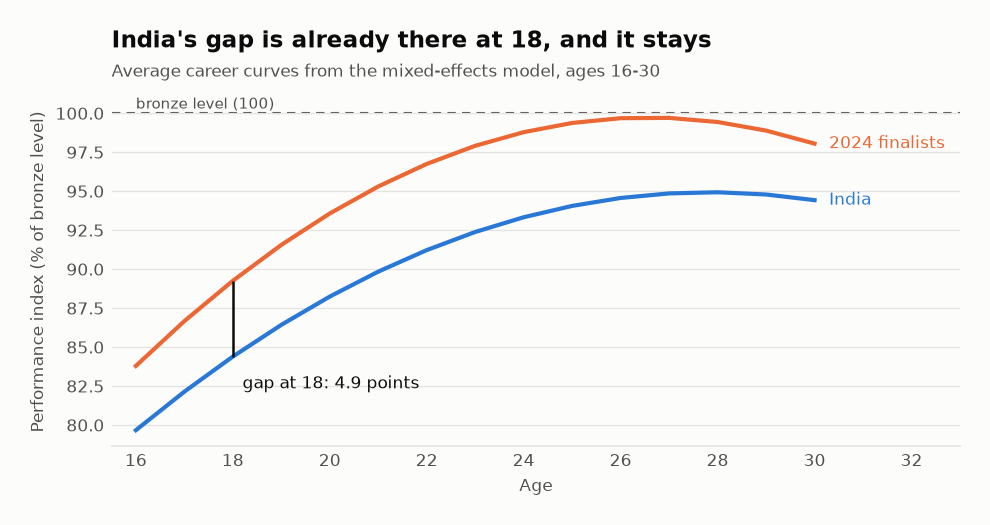

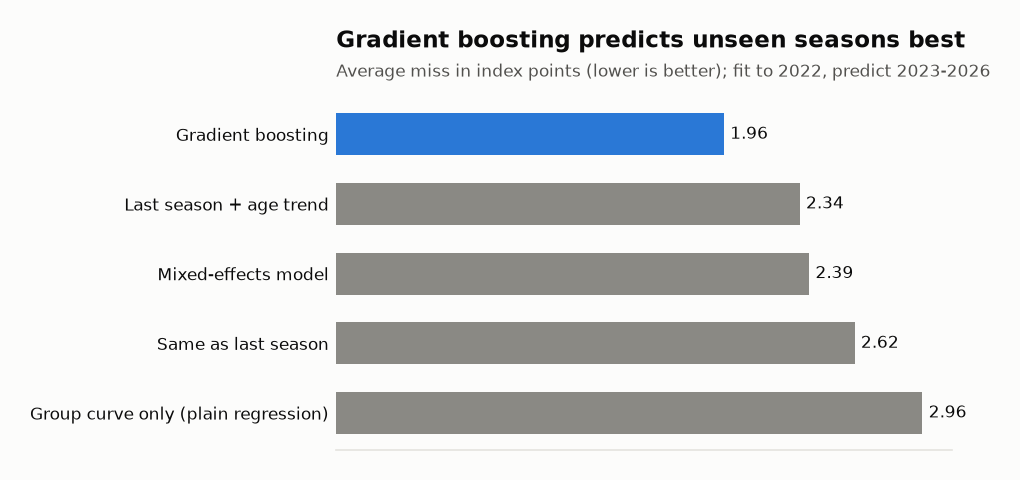

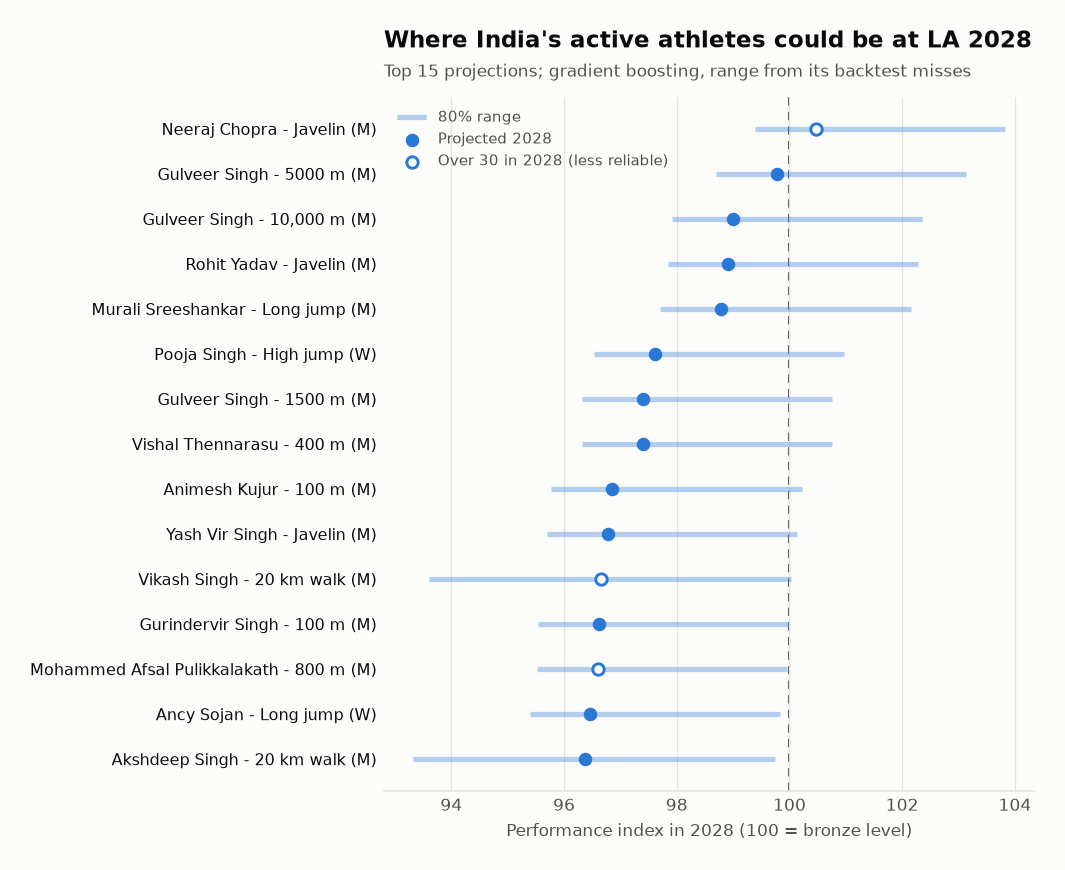

In [ ]:
from IPython.display import Image, display
from src import charts

out = ROOT / "docs" / "images"
paths = [
    charts.trajectory_chart(mean_curves(result), out / "phase4_curves.png"),
    charts.backtest_chart(scores, "boosting", out / "phase4_backtest.png"),
    charts.projections_chart(proj, out / "phase4_projections.png"),
]
for p in paths:
    display(Image(str(p)))

**Conclusion.** Boosting's lead over the mixed model is real overall (0.43 points, 95% CI 0.27 to
0.59, resampling athletes) and over the best simple rule (0.38, CI 0.21 to 0.55); for Indian
athletes the two tie (-0.05, CI -0.45 to 0.30). Boosting makes the projections, with 80% ranges
from its own backtest misses (split conformal); the mixed model remains the tool for explaining
the gap. 2028: of 44 active Indian athlete-events, only Neeraj Chopra is projected at bronze level
(100.5, range 99.4 to 103.8; aged 31, beyond the trained ages); ten more have ranges reaching 100.
Pooja Singh (high jump, 19) is the standout junior: 97.6 at 21 (96.5 to 101.0).